<a href="https://colab.research.google.com/github/FranciscoLopez27/acif104-brotes-eta/blob/main/notebooks/02_modelos_iniciales.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 02 · Modelos iniciales: 3 técnicas de ML y 3 arquitecturas de DL con 4 escenarios de balanceo
Se entrenan 24 combinaciones (6 técnicas × 4 escenarios de balanceo) y se comparan en **validación (2021–2022)**.
La evaluación en prueba se hace en el notebook 03, después del refinamiento.

Funciones utilizadas: `src/datos.py`, `src/balanceo.py`, `src/modelos_ml.py`, `src/redes.py` y `src/evaluacion.py`.

In [1]:
# Celda de preparación: funciona en Google Colab y en un entorno local (VS Code / Jupyter)
import sys, os
from pathlib import Path

if "google.colab" in sys.modules:
    if not Path("acif104-brotes-eta").exists():
        !git clone https://github.com/FranciscoLopez27/acif104-brotes-eta.git
    os.chdir("acif104-brotes-eta")
    !git pull -q
    !pip -q install imbalanced-learn shap
else:
    if Path.cwd().name == "notebooks":
        os.chdir("..")

sys.path.insert(0, os.getcwd())
print("Carpeta de trabajo:", os.getcwd())

Cloning into 'acif104-brotes-eta'...
remote: Enumerating objects: 64, done.
remote: Counting objects: 100% (64/64), done.
remote: Compressing objects: 100% (58/58), done.
remote: Total 64 (delta 21), reused 0 (delta 0), pack-reused 0 (from 0)
Receiving objects: 100% (64/64), 3.52 MiB | 13.20 MiB/s, done.
Resolving deltas: 100% (21/21), done.
Carpeta de trabajo: /content/acif104-brotes-eta


In [2]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src import datos as D, balanceo as B, evaluacion as E, modelos_ml as ML
from src.config import CAT, NUM, BALANCEOS, SEMILLA, AZUL, NARANJO, GRIS, VERDE, guardar, guardar_tabla

# Datos, partición y codificación (ajustada solo con entrenamiento)
p = D.particionar(D.preparar(D.cargar()))
cod = D.Codificador().fit(p["tr"][CAT + NUM])
M_tr, M_va = cod.transform(p["tr"][CAT + NUM]), cod.transform(p["va"][CAT + NUM])
y_tr, y_va = p["tr"].y.values, p["va"].y.values
print(M_tr.shape, M_va.shape, f"| línea base AUC-PR validación: {y_va.mean():.3f}")

# Escenarios de balanceo (solo entrenamiento)
datos_bal = {b: B.balancear(M_tr, y_tr, b, cod) for b in BALANCEOS}
tabla_bal = pd.DataFrame({b: {"Brotes de entrenamiento": len(v[1]), "% específico": round(v[1].mean() * 100, 1)}
                          for b, v in datos_bal.items()}).T
guardar_tabla(tabla_bal, "02_escenarios_balanceo")
tabla_bal

(8327, 15) (1424, 15) | línea base AUC-PR validación: 0.223


,Brotes de entrenamiento,% específico
Sin balanceo,8327.0,21.2
Ponderación de clases,8327.0,21.2
SMOTE-NC,13120.0,50.0
Submuestreo,3534.0,50.0


## 1. Técnicas de aprendizaje automático
Búsqueda en grilla de hiperparámetros (sin balanceo, criterio AUC-PR en validación).

In [3]:
mejores_params, busqueda = {}, []
for nombre, grilla in ML.GRILLAS.items():
    for params in grilla:
        m = ML.ajustar(ML.crear_modelo(nombre, params, cod), M_tr, y_tr)
        busqueda.append({"Modelo": nombre, "Parámetros": params,
                         "AUC-PR validación": round(E.average_precision_score(y_va, ML.probabilidad(m, M_va)), 4)})
    mejores_params[nombre] = max([b for b in busqueda if b["Modelo"] == nombre],
                                 key=lambda b: b["AUC-PR validación"])["Parámetros"]
guardar_tabla(pd.DataFrame(busqueda), "02_busqueda_hiperparametros_ml")
print(mejores_params)
pd.DataFrame(busqueda)

{'Regresión logística': {'C': 0.01}, 'Random Forest': {'max_depth': None, 'min_samples_leaf': 5}, 'Gradient boosting': {'learning_rate': 0.03, 'max_depth': 6, 'l2_regularization': 1.0}}


,Modelo,Parámetros,AUC-PR validación
0,Regresión logística,{'C': 0.01},0.4944
1,Regresión logística,{'C': 0.1},0.4915
2,Regresión logística,{'C': 1.0},0.4731
3,Random Forest,"{'max_depth': 8, 'min_samples_leaf': 5}",0.5857
4,Random Forest,"{'max_depth': 8, 'min_samples_leaf': 20}",0.5560
5,Random Forest,"{'max_depth': 16, 'min_samples_leaf': 5}",0.6064
6,Random Forest,"{'max_depth': 16, 'min_samples_leaf': 20}",0.5712
7,Random Forest,"{'max_depth': None, 'min_samples_leaf': 5}",0.6212
8,Random Forest,"{'max_depth': None, 'min_samples_leaf': 20}",0.5741
9,Gradient boosting,"{'learning_rate': 0.03, 'max_depth': 3, 'l2_re...",0.5787


In [4]:
resultados, probas_va = [], {}
for nombre in ML.MODELOS_ML:
    for bal in BALANCEOS:
        Mb, yb, w = datos_bal[bal]
        t0 = time.time()
        m = ML.ajustar(ML.crear_modelo(nombre, mejores_params[nombre], cod), Mb, yb, w)
        seg = time.time() - t0
        pr = ML.probabilidad(m, M_va)
        resultados.append({"Familia": "ML", "Modelo": nombre, "Balanceo": bal,
                           **E.metricas(y_va, pr, E.umbral_para_recall(y_va, pr)), "Entrenamiento (s)": seg})
        probas_va[(nombre, bal)] = pr
res_ml = pd.DataFrame(resultados)
res_ml.round(3)

,Familia,Modelo,Balanceo,AUC-PR,AUC-ROC,Recall,Precisión,F1,Exactitud bal.,Brier,Umbral,Entrenamiento (s)
0,ML,Regresión logística,Sin balanceo,0.494,0.798,0.7,0.437,0.538,0.721,0.146,0.179,0.043
1,ML,Regresión logística,Ponderación de clases,0.495,0.801,0.7,0.439,0.539,0.722,0.178,0.449,0.047
2,ML,Regresión logística,SMOTE-NC,0.494,0.794,0.7,0.447,0.545,0.726,0.170,0.442,0.071
3,ML,Regresión logística,Submuestreo,0.497,0.797,0.7,0.424,0.528,0.714,0.185,0.455,0.024
4,ML,Random Forest,Sin balanceo,0.621,0.840,0.7,0.538,0.608,0.764,0.127,0.264,2.972
5,ML,Random Forest,Ponderación de clases,0.634,0.843,0.7,0.496,0.580,0.748,0.131,0.391,2.460
6,ML,Random Forest,SMOTE-NC,0.613,0.845,0.7,0.517,0.595,0.757,0.131,0.396,5.234
7,ML,Random Forest,Submuestreo,0.590,0.829,0.7,0.482,0.571,0.742,0.160,0.490,1.411
8,ML,Gradient boosting,Sin balanceo,0.623,0.836,0.7,0.496,0.580,0.748,0.127,0.196,1.198
9,ML,Gradient boosting,Ponderación de clases,0.602,0.831,0.7,0.499,0.583,0.749,0.139,0.419,1.246


## 2. Arquitecturas de aprendizaje profundo (PyTorch)
MLP, MLP con *embeddings* y Transformer tabular, con parada temprana según el AUC-PR de validación.
La ponderación de clases se aplica con `pos_weight` en la función de pérdida.

In [5]:
from src import redes as R
print("Dispositivo:", R.DISPOSITIVO)
prep = R.PreparadorRed(cod).fit(M_tr)

resultados_dl, historiales = [], {}
for nombre in R.ARQUITECTURAS:
    for bal in BALANCEOS:
        Mb, yb, w = datos_bal[bal]
        t0 = time.time()
        modelo, ep, hist = R.entrenar_red(nombre, prep, Mb, yb, M_va, y_va, ponderar=(bal == "Ponderación de clases"))
        seg = time.time() - t0
        pr = R.predecir(modelo, *prep.tensores(M_va))
        resultados_dl.append({"Familia": "DL", "Modelo": nombre, "Balanceo": bal,
                              **E.metricas(y_va, pr, E.umbral_para_recall(y_va, pr)),
                              "Entrenamiento (s)": seg, "Épocas": ep, "Parámetros": R.contar_parametros(modelo)})
        probas_va[(nombre, bal)] = pr
        historiales[(nombre, bal)] = hist
        print(f"{nombre:22s} | {bal:22s} | AUC-PR {resultados_dl[-1]['AUC-PR']:.3f} | mejor época {ep} | {seg:.0f} s")
res_dl = pd.DataFrame(resultados_dl)
res_dl.round(3)

Dispositivo: cuda
MLP                    | Sin balanceo           | AUC-PR 0.591 | mejor época 11 | 8 s
MLP                    | Ponderación de clases  | AUC-PR 0.603 | mejor época 16 | 2 s
MLP                    | SMOTE-NC               | AUC-PR 0.577 | mejor época 24 | 5 s
MLP                    | Submuestreo            | AUC-PR 0.557 | mejor época 14 | 1 s
MLP con embeddings     | Sin balanceo           | AUC-PR 0.576 | mejor época 36 | 5 s
MLP con embeddings     | Ponderación de clases  | AUC-PR 0.561 | mejor época 23 | 3 s
MLP con embeddings     | SMOTE-NC               | AUC-PR 0.565 | mejor época 24 | 6 s
MLP con embeddings     | Submuestreo            | AUC-PR 0.533 | mejor época 22 | 1 s
Transformer tabular    | Sin balanceo           | AUC-PR 0.574 | mejor época 44 | 14 s
Transformer tabular    | Ponderación de clases  | AUC-PR 0.545 | mejor época 52 | 18 s
Transformer tabular    | SMOTE-NC               | AUC-PR 0.517 | mejor época 2 | 4 s
Transformer tabular    | Submuestre

,Familia,Modelo,Balanceo,AUC-PR,AUC-ROC,Recall,Precisión,F1,Exactitud bal.,Brier,Umbral,Entrenamiento (s),Épocas,Parámetros
0,DL,MLP,Sin balanceo,0.591,0.826,0.7,0.502,0.585,0.751,0.140,0.140,7.949,11,41985
1,DL,MLP,Ponderación de clases,0.603,0.826,0.7,0.476,0.567,0.740,0.148,0.455,2.114,16,41985
2,DL,MLP,SMOTE-NC,0.577,0.816,0.7,0.451,0.549,0.728,0.143,0.122,4.720,24,41985
3,DL,MLP,Submuestreo,0.557,0.825,0.7,0.486,0.574,0.744,0.157,0.489,0.825,14,41985
4,DL,MLP con embeddings,Sin balanceo,0.576,0.817,0.7,0.471,0.563,0.738,0.136,0.148,4.526,36,22759
5,DL,MLP con embeddings,Ponderación de clases,0.561,0.816,0.7,0.457,0.553,0.731,0.162,0.505,3.470,23,22759
6,DL,MLP con embeddings,SMOTE-NC,0.565,0.812,0.7,0.456,0.552,0.730,0.148,0.346,5.568,24,22759
7,DL,MLP con embeddings,Submuestreo,0.533,0.805,0.7,0.441,0.541,0.723,0.189,0.558,1.414,22,22759
8,DL,Transformer tabular,Sin balanceo,0.574,0.830,0.7,0.508,0.589,0.753,0.130,0.254,14.436,44,25825
9,DL,Transformer tabular,Ponderación de clases,0.545,0.824,0.7,0.484,0.572,0.743,0.162,0.520,17.876,52,25825


## 3. Comparación de las 24 combinaciones

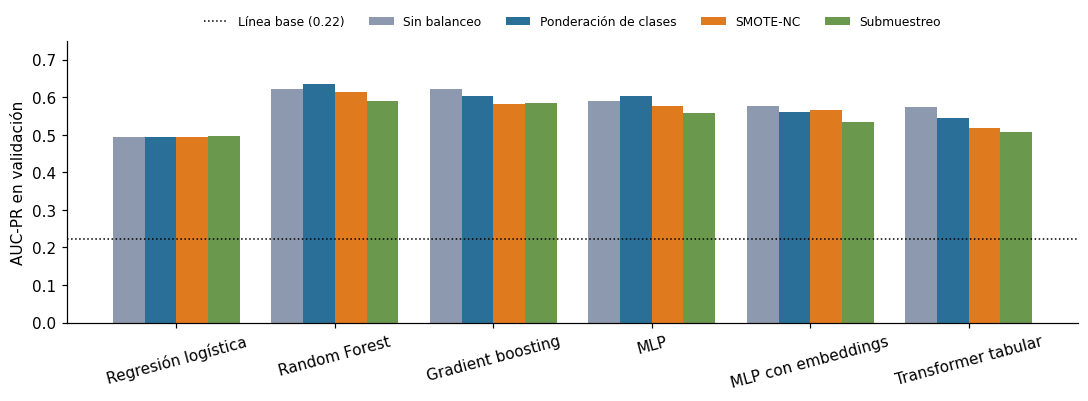

Balanceo,Sin balanceo,Ponderación de clases,SMOTE-NC,Submuestreo
Modelo,,,,
Regresión logística,0.494,0.495,0.494,0.497
Random Forest,0.621,0.634,0.613,0.590
Gradient boosting,0.623,0.602,0.582,0.584
MLP,0.591,0.603,0.577,0.557
MLP con embeddings,0.576,0.561,0.565,0.533
Transformer tabular,0.574,0.545,0.517,0.508


In [6]:
res = pd.concat([res_ml, res_dl], ignore_index=True)
guardar_tabla(res, "02_validacion_24_combinaciones")
orden = ML.MODELOS_ML + list(R.ARQUITECTURAS)
tabla_ap = res.pivot(index="Modelo", columns="Balanceo", values="AUC-PR").loc[orden, BALANCEOS]
guardar_tabla(tabla_ap, "02_auc_pr_por_balanceo")

fig, ax = plt.subplots(figsize=(10, 3.8))
ancho = 0.8 / len(BALANCEOS)
for i, (bal, color) in enumerate(zip(BALANCEOS, [GRIS, AZUL, NARANJO, VERDE])):
    ax.bar(np.arange(len(tabla_ap)) + i * ancho - 0.4 + ancho / 2, tabla_ap[bal], ancho, label=bal, color=color)
ax.axhline(y_va.mean(), color="black", ls=":", lw=1, label=f"Línea base ({y_va.mean():.2f})")
ax.set_xticks(range(len(tabla_ap)), tabla_ap.index, rotation=15)
ax.set_ylabel("AUC-PR en validación")
ax.set_ylim(0, 0.75)
ax.legend(ncol=5, fontsize=8, frameon=False, loc="upper center", bbox_to_anchor=(0.5, 1.13))
guardar(fig, "fig_comparacion_balanceo.png")
tabla_ap.round(3)

## 4. Efecto del balanceo
Promedio de las 6 técnicas por escenario, con el umbral para exhaustividad ≥ 0,70 y con el umbral por defecto (0,5).

In [7]:
efecto = res.groupby("Balanceo")[["AUC-PR", "AUC-ROC", "Recall", "Precisión", "F1", "Brier"]].mean().loc[BALANCEOS]
uf = []
for (nombre, bal), pr in probas_va.items():
    pred = (pr >= 0.5).astype(int)
    uf.append({"Balanceo": bal, "Recall (umbral 0,5)": E.recall_score(y_va, pred),
               "Precisión (umbral 0,5)": E.precision_score(y_va, pred, zero_division=0)})
uf = pd.DataFrame(uf).groupby("Balanceo").mean().loc[BALANCEOS]
efecto_balanceo = pd.concat([efecto, uf], axis=1)
guardar_tabla(efecto_balanceo, "02_efecto_balanceo")
efecto_balanceo.round(3)

,AUC-PR,AUC-ROC,Recall,Precisión,F1,Brier,"Recall (umbral 0,5)","Precisión (umbral 0,5)"
Balanceo,,,,,,,,
Sin balanceo,0.580,0.825,0.7,0.492,0.577,0.134,0.270,0.681
Ponderación de clases,0.573,0.824,0.7,0.475,0.566,0.153,0.648,0.505
SMOTE-NC,0.558,0.818,0.7,0.473,0.564,0.147,0.536,0.535
Submuestreo,0.545,0.812,0.7,0.459,0.554,0.172,0.685,0.466


## 5. Convergencia de las redes (escenario sin balanceo)
Pérdida de entrenamiento y de validación por época. Si la de validación sube mientras la de entrenamiento baja, hay sobreajuste.

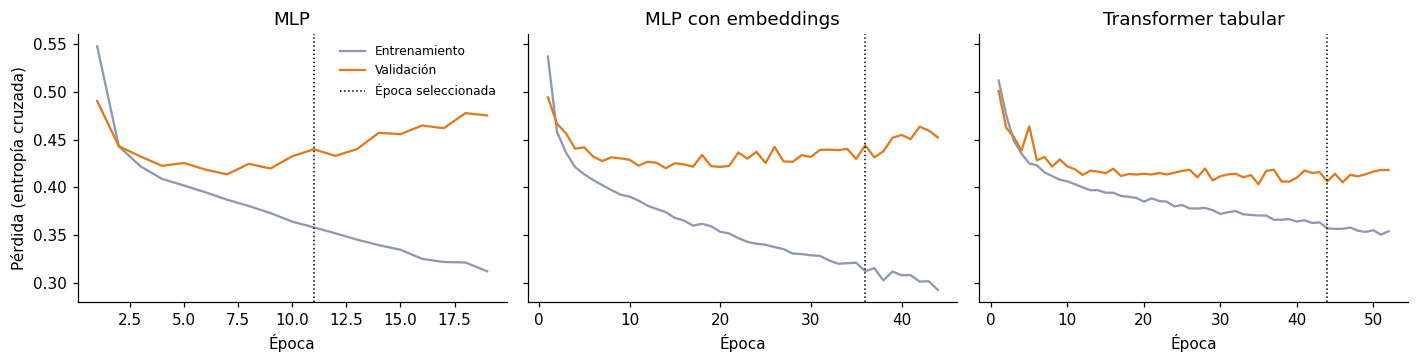

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.4), sharey=True)
for ax, nombre in zip(axes, R.ARQUITECTURAS):
    h = historiales[(nombre, "Sin balanceo")]
    ep = int(res_dl.loc[(res_dl.Modelo == nombre) & (res_dl.Balanceo == "Sin balanceo"), "Épocas"].iloc[0])
    ax.plot(range(1, len(h["perdida_tr"]) + 1), h["perdida_tr"], color=GRIS, label="Entrenamiento")
    ax.plot(range(1, len(h["perdida_va"]) + 1), h["perdida_va"], color=NARANJO, label="Validación")
    ax.axvline(ep, color="black", ls=":", lw=1, label="Época seleccionada")
    ax.set_title(nombre)
    ax.set_xlabel("Época")
axes[0].set_ylabel("Pérdida (entropía cruzada)")
axes[0].legend(frameon=False, fontsize=8)
guardar(fig, "fig_convergencia_redes.png")